# DepositIQ 03 — Exploratory Data Analysis

**Rubric:** Criterion 4 — EDA · **Task:** T16 · **Phase:** 4
**Dataset:** `data/processed/train.csv` — the **training half only**, 36,168 × 19, loaded through
[src/split.py](../src/split.py)
**Depends on:** T15 ([src/split.py](../src/split.py)) for the fixed, stratified split, and T12
([src/clean.py](../src/clean.py)) for the cleaned frame underneath it.

## What this notebook does

T15 froze the evaluation halves. This notebook reads **only the training one** and starts the EDA:

- **§1 Target distribution and class imbalance** (T16, this notebook) — how many clients subscribed,
  how lopsided the class balance is, and which evaluation baselines that distribution *forces* on the
  rest of the project.

Sections **§2–§5 are reserved for T17–T20** (numeric distributions, categorical rates, campaign
features, correlation) so that the EDA lands as one notebook with figure numbers `01_`–`05_` rather
than five files.

## Why the training half only

The test half must stay unseen until T32, or it stops being a held-out test. Everything below is
measured on `train.csv`; the one place the source population appears is the split-sanity line in §1.5,
which quotes the **label rate only** that T15 already published — no test features are touched, and
`test.csv` is not read anywhere in this notebook.

## Two decisions this section already answers

1. **D04 — accuracy is not a headline metric.** §1.3 quantifies the trivial classifier that exploits
   the imbalance and shows what it scores.
2. **D15 — the honest baselines.** PR-AUC is read against the *positive rate*, not 0.5; ROC-AUC
   against 0.5.

## Setup

Same path handling as T11/T13 (decision D12), so the notebook runs from any working directory. The
training half is loaded through `split.load_split` rather than a bare `read_csv`, so there is one
place that knows how these files are read — and the load is asserted to be `train.csv`, not the test
file.

In [1]:
import platform
import sys
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold


def find_repo_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "src" / "config.py").exists():
            return candidate
    raise RuntimeError("Could not find the repository root above " + str(start))


REPO_ROOT = find_repo_root(Path.cwd())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src import config                  # noqa: E402
from src import data_loader as load     # noqa: E402
from src import split                   # noqa: E402

config.ensure_dirs()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")

TRAIN_PATH = config.TRAIN_CSV
TRAIN = split.load_split("full", "train")

# Provenance guard: this notebook must be looking at the training half, and it must be the file
# T15 wrote. The test half is deliberately not loaded anywhere in this notebook.
assert TRAIN_PATH == split.SPLITS["full"][0], "this notebook must read the train split, not the test"
assert TRAIN_PATH.name == "train.csv"
assert config.TEST_CSV.name not in TRAIN_PATH.name

print("Executed  :", datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print("Python    :", platform.python_version())
print("Source    :", TRAIN_PATH.relative_to(REPO_ROOT), "->", tuple(TRAIN.shape))
print("Test file :", config.TEST_CSV.name, "not read by this notebook (held out until T32)")

Executed  : 2026-10-27 20:07:24
Python    : 3.11.9
Source    : data\processed\train.csv -> (36168, 19)
Test file : test.csv not read by this notebook (held out until T32)


## 1. Target distribution and class imbalance (T16)

The target is `y`: `yes` = the client subscribed to a term deposit. The first question of any
classification project is simply *how many of each class are there*, because that single number
decides what counts as a good model.

In [2]:
counts = TRAIN[config.TARGET].value_counts()
order = [config.NEGATIVE_LABEL, config.POSITIVE_LABEL]          # no first, yes second
counts = counts.reindex(order)

n_total = int(counts.sum())
n_yes = int(counts[config.POSITIVE_LABEL])
n_no = int(counts[config.NEGATIVE_LABEL])
rate = n_yes / n_total
imbalance_ratio = n_no / n_yes

summary = pd.DataFrame({
    "class": [f"{config.NEGATIVE_LABEL}  (did not subscribe)", f"{config.POSITIVE_LABEL}  (subscribed)"],
    "count": [n_no, n_yes],
    "share": [n_no / n_total, n_yes / n_total],
})
summary["cumulative"] = summary["share"].cumsum().values

print(f"training half : {TRAIN_PATH.name}  ({n_total:,} rows)")
print()
print(summary.to_string(index=False, formatters={"share": "{:.4%}".format, "cumulative": "{:.4%}".format}))
print()
print(f"positive rate : {n_yes:,} / {n_total:,} = {rate:.4%}")
print(f"imbalance     : {n_no:,} : {n_yes:,} = {imbalance_ratio:.2f} : 1")
print(f"majority class: {n_no / n_total:.4%} of the half -> the trivial 'always no' score")

training half : train.csv  (36,168 rows)

                  class  count    share cumulative
no  (did not subscribe)  31937 88.3018%   88.3018%
      yes  (subscribed)   4231 11.6982%  100.0000%

positive rate : 4,231 / 36,168 = 11.6982%
imbalance     : 31,937 : 4,231 = 7.55 : 1
majority class: 88.3018% of the half -> the trivial 'always no' score


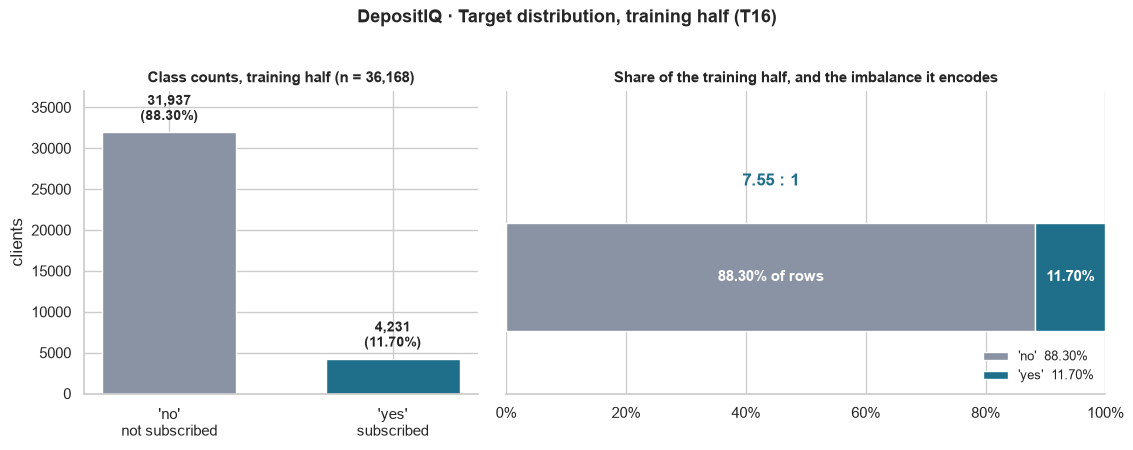

saved: reports\figures\01_target_distribution.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={"width_ratios": [1.05, 1.6]})
palette = {config.NEGATIVE_LABEL: "#8a93a3", config.POSITIVE_LABEL: "#1f6f8b"}

# Panel A - raw counts. The minority bar is the whole point of the figure.
ax = axes[0]
bars = ax.bar([f"'{config.NEGATIVE_LABEL}'\nnot subscribed", f"'{config.POSITIVE_LABEL}'\nsubscribed"],
              [n_no, n_yes], color=[palette[config.NEGATIVE_LABEL], palette[config.POSITIVE_LABEL]],
              width=0.6)
for bar, value, share in zip(bars, [n_no, n_yes], [n_no / n_total, n_yes / n_total]):
    ax.annotate(f"{value:,}\n({share:.2%})",
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 6), textcoords="offset points",
                ha="center", va="bottom", fontsize=10, weight="bold")
ax.set_ylim(0, n_no * 1.16)
ax.set_ylabel("clients")
ax.set_title(f"Class counts, training half (n = {n_total:,})", fontsize=11, weight="bold")
ax.spines[["top", "right"]].set_visible(False)

# Panel B - the same data as shares, with the ratio that governs evaluation.
ax = axes[1]
ax.barh([0], [n_no / n_total], color=palette[config.NEGATIVE_LABEL], height=0.42,
        label=f"'{config.NEGATIVE_LABEL}'  {n_no / n_total:.2%}")
ax.barh([0], [n_yes / n_total], left=[n_no / n_total], color=palette[config.POSITIVE_LABEL], height=0.42,
        label=f"'{config.POSITIVE_LABEL}'  {n_yes / n_total:.2%}")
ax.annotate(f"{n_no / n_total:.2%} of rows", xy=(n_no / n_total / 2, 0), ha="center", va="center",
            color="white", fontsize=11, weight="bold")
ax.annotate(f"{n_yes / n_total:.2%}", xy=(n_no / n_total + n_yes / n_total / 2, 0), ha="center", va="center",
            color="white", fontsize=11, weight="bold")
ax.annotate(f"{imbalance_ratio:.2f} : 1", xy=(n_no / n_total / 2, 0.34), ha="center", va="bottom",
            fontsize=12, weight="bold", color="#1f6f8b")
ax.set_xlim(0, 1)
ax.set_ylim(-0.45, 0.72)
ax.set_yticks([])
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_title("Share of the training half, and the imbalance it encodes", fontsize=11, weight="bold")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=9)

fig.suptitle("DepositIQ · Target distribution, training half (T16)", fontsize=13, weight="bold", y=1.02)
fig.tight_layout()
figure_path = config.FIGURES_DIR / "01_target_distribution.png"
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()
print("saved:", figure_path.relative_to(REPO_ROOT))

> **Viva line for this figure:** *eleven point seven percent of the training half subscribed* — so
> a model that always answers "no" scores **88.3% accuracy** while producing nothing, which is
> exactly why this project reports **PR-AUC against a 0.117 random baseline** instead of accuracy
> (D04, D15).

### 1.1 What the distribution forces us to report

The imbalance is not a cosmetic detail: it sets the score a trivial model gets. Every number below is
derived from the counts above, so the evaluation section (T32–T35) cannot quietly drift away from
them.

In [4]:
trivial_always_no = n_no / n_total                 # predicts 'no' for everyone
pr_auc_random = rate                               # a random scorer's average precision == base rate
roc_auc_random = 0.5                               # a random scorer's ROC-AUC
per_call_yield = rate                              # expected subscriptions per call at random
calls_per_subscription = 1 / rate

baselines = pd.DataFrame([
    ["Accuracy, always predict 'no'", f"{trivial_always_no:.4%}", "0 (no subscriptions found)",
     "D04: why accuracy is not the headline"],
    ["Accuracy, always predict 'yes'", f"{rate:.4%}", "every client flagged",
     "the other degenerate classifier"],
    ["PR-AUC (average precision)", f"{pr_auc_random:.4%}", f"{pr_auc_random:.4f}",
     "D15: the value the model must beat"],
    ["ROC-AUC", "50.0000%", "0.5000", "D15: the other honest baseline"],
], columns=["metric", "trivial score", "what it means", "why it matters"])

print(baselines.to_string(index=False))
print()
print(f"At the base rate a random campaign yields {per_call_yield:.4%} subscriptions per call,")
print(f"i.e. about {calls_per_subscription:.2f} calls per subscription to reach one {config.POSITIVE_LABEL!r}.")

                        metric trivial score              what it means                        why it matters
 Accuracy, always predict 'no'      88.3018% 0 (no subscriptions found) D04: why accuracy is not the headline
Accuracy, always predict 'yes'      11.6982%       every client flagged       the other degenerate classifier
    PR-AUC (average precision)      11.6982%                     0.1170    D15: the value the model must beat
                       ROC-AUC      50.0000%                     0.5000        D15: the other honest baseline

At the base rate a random campaign yields 11.6982% subscriptions per call,
i.e. about 8.55 calls per subscription to reach one 'yes'.


### 1.2 Where the training half came from

T15's split was stratified (D26), so the training half should reproduce the source population's label
rate almost exactly. The population rate is quoted from the raw file through the loader — the **label
only**, which T15 already published; the held-out half's rows are not part of this section.

In [5]:
population = load.load_raw("full", verbose=False)
population_rate = float((population[config.TARGET] == config.POSITIVE_LABEL).mean())

delta = rate - population_rate
print(f"source population  : {len(population):,} rows, y == 'yes' {population_rate:.6%}")
print(f"training half      : {n_total:,} rows, y == 'yes' {rate:.6%}")
print(f"difference         : {delta * 100:+.6f} pp")
print()
print("Both are far inside the +/-1pp the split was graded on (T15), so the EDA below describes the")
print("same population as the raw file - the split did not distort the target.")

source population  : 45,211 rows, y == 'yes' 11.698480%
training half      : 36,168 rows, y == 'yes' 11.698186%
difference         : -0.000294 pp

Both are far inside the +/-1pp the split was graded on (T15), so the EDA below describes the
same population as the raw file - the split did not distort the target.


### 1.3 What the imbalance means for validation

The counts above also fix how the model can be validated: a fold-level metric is only as stable as
the number of positives that land in each fold. This is measured rather than assumed, because it is the
justification for the fold count T30 will use.


In [6]:
# How many positives each validation fold would hold under 5-fold stratified CV (T30's design).
n_folds = 5
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=config.RANDOM_STATE)
fold_rows = []
for fold, (_, val_index) in enumerate(skf.split(TRAIN, TRAIN[config.TARGET]), start=1):
    fold_yes = int((TRAIN[config.TARGET].iloc[val_index] == config.POSITIVE_LABEL).sum())
    fold_rows.append({"fold": fold, "val rows": len(val_index), "positives": fold_yes,
                      "val rate": fold_yes / len(val_index)})
fold_table = pd.DataFrame(fold_rows)

print(f"{n_folds}-fold stratified CV over the training half ({n_total:,} rows)")
print(fold_table.to_string(index=False, formatters={"val rate": "{:.4%}".format}))
print()
print(f"Every validation fold carries at least {int(fold_table['positives'].min()):,} positives, so a")
print("fold-level metric rests on a denominator big enough to be stable - the measured reason T30")
print("uses 5 folds rather than 10 (10 would halve this denominator for no gain in precision).")

5-fold stratified CV over the training half (36,168 rows)
 fold  val rows  positives val rate
    1      7234        846 11.6948%
    2      7234        846 11.6948%
    3      7234        847 11.7086%
    4      7233        846 11.6964%
    5      7233        846 11.6964%

Every validation fold carries at least 846 positives, so a
fold-level metric rests on a denominator big enough to be stable - the measured reason T30
uses 5 folds rather than 10 (10 would halve this denominator for no gain in precision).


In [7]:
# Evidence: the numbers this section states must be the numbers the data gives.
assert len(TRAIN) == 36168, len(TRAIN)
assert n_yes == 4231 and n_no == 31937, (n_yes, n_no)
assert abs(rate - 0.1169819) < 1e-7, rate
assert round(imbalance_ratio, 2) == 7.55, imbalance_ratio
assert abs(trivial_always_no - 0.8830181) < 1e-7, trivial_always_no
assert abs(pr_auc_random - rate) < 1e-12 and roc_auc_random == 0.5
assert abs(per_call_yield - rate) < 1e-12 and abs(calls_per_subscription - 1 / rate) < 1e-12
assert set(TRAIN[config.TARGET].unique()) == {"no", "yes"}
assert TRAIN_PATH.name == "train.csv" and config.TEST_CSV.name not in TRAIN_PATH.name
assert abs(delta) < 0.0001, delta                      # stratified split reproduces the population
assert len(fold_table) == 5 and fold_table["positives"].sum() == n_yes
assert figure_path.exists() and figure_path.stat().st_size > 20_000
assert figure_path.name == "01_target_distribution.png"
print("evidence: 13 assertion lines pass")

evidence: 13 assertion lines pass


## 2. Findings, and what they hand to the next tasks

1. **The training half is 36,168 calls: 4,231 subscribed (11.6982%), 31,937 did not (88.3018%) —
   a 7.55 : 1 imbalance.** The rate reproduces the source population's 11.6985% to within 0.0003 pp,
   which is the stratified split (D26) doing its job; EDA here therefore describes the same
   population as the raw file.
2. **Accuracy is disqualified by construction (D04).** An always-"no" classifier scores **88.3018%**
   accuracy on this half while finding zero subscribers, and an always-"yes" classifier scores
   11.6982% while flagging everyone. Accuracy is reported only alongside PR-AUC/ROC-AUC, never alone.
3. **The PR-AUC baseline is 0.1170, not 0.5.** A random scorer's average precision equals the
   positive rate, so "PR-AUC = 0.6" is a 5× lift over random rather than a barely-above-chance score;
   ROC-AUC keeps its 0.5 baseline. This is the reading D15's targets depend on.
4. **The validation design follows from the counts.** With 4,231 positives, 5-fold stratified CV
   gives every validation fold a few hundred positives — enough that a fold-level metric is stable —
   while a 10-fold split would halve that denominator for no gain. This is the measured justification
   for the 5-fold `StratifiedKFold` in T30, decided from the data rather than inherited as a default.
5. **The base rate is also the business denominator.** At random, one subscription costs about
   **8.55 calls**, and   the break-even threshold p\* = 7.50% (D17) sits *below* the 11.70% base rate —
   so calling the average client is still positive-EV (EV +€0.84), which is precisely why D18 scopes
   the claim to *converting a fixed call budget better* rather than to cutting spend.

**Nothing here is a model result.** Every figure is a property of the training data; no classifier has
been fitted yet, and the test half has not been opened.

## 3. Reproducibility record

In [8]:
print("Notebook   : notebooks/03_eda.ipynb  (T16, rubric criterion 4)")
print("Executed   :", datetime.now().isoformat(timespec="seconds"))
print("Dataset    :", TRAIN_PATH.relative_to(REPO_ROOT), tuple(TRAIN.shape),
      f"(target {rate:.4%})")
print("Section    : 1 - target distribution and class imbalance (T16)")
print("Baselines  :", f"accuracy {trivial_always_no:.4%} | PR-AUC {pr_auc_random:.4f} | ROC-AUC 0.5")
print("Held out   :", config.TEST_CSV.name, "not read")
print("Figures    :")
for path in sorted(config.FIGURES_DIR.glob("01_*.png")):
    print(f"   {path.name:<44} {path.stat().st_size / 1024:>6.0f} KB")
print()
print("Rerun with : jupyter nbconvert --to notebook --execute --inplace notebooks/03_eda.ipynb")
print("Next task  : T17 - numeric distributions and skew into 02_numeric_distributions.png")

Notebook   : notebooks/03_eda.ipynb  (T16, rubric criterion 4)
Executed   : 2026-10-27T20:07:26
Dataset    : data\processed\train.csv (36168, 19) (target 11.6982%)
Section    : 1 - target distribution and class imbalance (T16)
Baselines  : accuracy 88.3018% | PR-AUC 0.1170 | ROC-AUC 0.5
Held out   : test.csv not read
Figures    :
   01_target_distribution.png                       66 KB

Rerun with : jupyter nbconvert --to notebook --execute --inplace notebooks/03_eda.ipynb
Next task  : T17 - numeric distributions and skew into 02_numeric_distributions.png
